Test Accuracy on new dataset: 0.08471352354442124


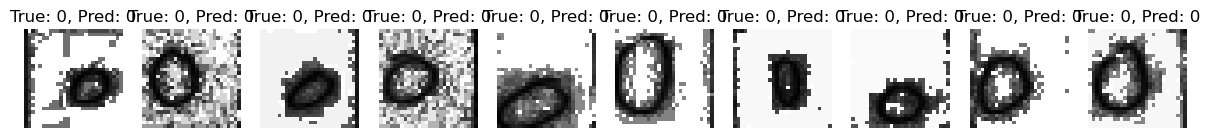

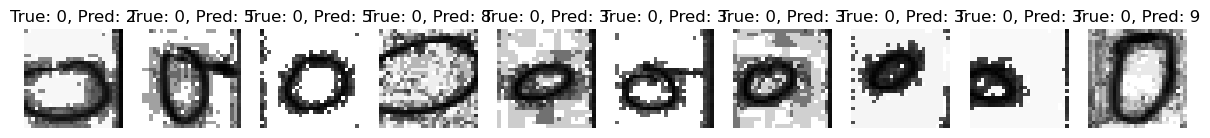

In [32]:
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from tensorflow.keras.datasets import mnist

# Load the model parameters
def load_model(file_path):
    npzfile = np.load(file_path)
    W1 = npzfile['W1']
    b1 = npzfile['b1']
    W2 = npzfile['W2']
    b2 = npzfile['b2']
    return W1, b1, W2, b2

# Load new dataset images with histogram equalization
def load_images_from_folder(folder):
    images = []
    labels = []
    for label in range(10):  # Assuming folders are named from '0' to '9'
        label_folder = os.path.join(folder, str(label))
        for filename in os.listdir(label_folder):
            img_path = os.path.join(label_folder, filename)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Read the image in grayscale
            if img is not None:
                img_resized = cv2.resize(img, (28, 28))  # Resize to 28x28
                img_equalized = cv2.equalizeHist(img_resized)  # Apply histogram equalization
                images.append(img_equalized)
                labels.append(label)
    return np.array(images), np.array(labels)

# Flatten the images
def flatten_images(images):
    return images.reshape(images.shape[0], -1)  # Flatten the images

# One-hot encode the labels
def one_hot_encode(labels, num_classes):  # One-hot encode the labels
    return np.eye(num_classes)[labels]  # Return the one-hot encoded labels

# Normalize the data between 0 and 1 by dividing by 255
def normalize_data(images):  # Normalize the data
    return images / 255.0  # Normalize the data

# Forward propagation function
def forward_propagation(X, W1, b1, W2, b2, keep_prob=1.0):  # Forward propagation
    Z1 = np.dot(W1, X) + b1  # Compute the weighted sum of the inputs
    A1 = relu(Z1)  # Apply the ReLU activation function
    Z2 = np.dot(W2, A1) + b2  # Compute the weighted sum of the hidden layer
    A2 = softmax(Z2)  # Apply the softmax activation function
    return Z1, A1, Z2, A2  # Return the intermediate outputs

# Activation functions
def relu(x):
    return np.maximum(0, x)  # ReLU activation function

def softmax(x):
    exps = np.exp(x - np.max(x, axis=0, keepdims=True))  # Subtract the maximum value to prevent overflow
    return exps / np.sum(exps, axis=0, keepdims=True)  # Softmax activation function

# Evaluate the model and return correctly and misclassified images
def evaluate_model_with_classifications(X_test, y_test, W1, b1, W2, b2):
    _, _, _, A2 = forward_propagation(X_test.T, W1, b1, W2, b2, keep_prob=1.0)  # No dropout during evaluation
    predictions = np.argmax(A2, axis=0)
    labels = np.argmax(y_test.T, axis=0)
    accuracy = np.mean(predictions == labels)
    
    # Identify misclassified examples
    misclassified_indices = np.where(predictions != labels)[0]
    misclassified_images = X_test[misclassified_indices]
    misclassified_labels = labels[misclassified_indices]
    misclassified_predictions = predictions[misclassified_indices]
    
    # Identify correctly classified examples
    correctly_classified_indices = np.where(predictions == labels)[0]
    correctly_classified_images = X_test[correctly_classified_indices]
    correctly_classified_labels = labels[correctly_classified_indices]
    correctly_classified_predictions = predictions[correctly_classified_indices]
    
    return accuracy, misclassified_images, misclassified_labels, misclassified_predictions, correctly_classified_images, correctly_classified_labels, correctly_classified_predictions

# Visualize correctly classified examples
def visualize_correctly_classified_images(images, true_labels, predicted_labels, num_samples=10):
    plt.figure(figsize=(15, 15))
    for i in range(min(num_samples, len(images))):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(images[i].reshape(28, 28), cmap='gray')
        plt.title(f"True: {true_labels[i]}, Pred: {predicted_labels[i]}")
        plt.axis('off')
    plt.show()

# Load and preprocess the new dataset
dataset_path = '/Users/borisivanov/Documents/GitHub/mnist_neural_network/archive'
images, labels = load_images_from_folder(dataset_path)
images_flattened = flatten_images(images)
labels_one_hot = one_hot_encode(labels, 10)
images_normalized = normalize_data(images_flattened)

# Load the saved model
model_path = "/Users/borisivanov/Documents/GitHub/mnist_neural_network/mnist_model.npz"
W1, b1, W2, b2 = load_model(model_path)

# Evaluate the model and get correctly and misclassified examples
accuracy, misclassified_images, misclassified_labels, misclassified_predictions, correctly_classified_images, correctly_classified_labels, correctly_classified_predictions = evaluate_model_with_classifications(images_normalized, labels_one_hot, W1, b1, W2, b2)
print(f"Test Accuracy on new dataset: {accuracy}")

# Visualize correctly classified examples
visualize_correctly_classified_images(correctly_classified_images, correctly_classified_labels, correctly_classified_predictions)

# Visualize misclassified examples
def visualize_misclassified_images(images, true_labels, predicted_labels, num_samples=10):
    plt.figure(figsize=(15, 15))
    for i in range(min(num_samples, len(images))):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(images[i].reshape(28, 28), cmap='gray')
        plt.title(f"True: {true_labels[i]}, Pred: {predicted_labels[i]}")
        plt.axis('off')
    plt.show()

visualize_misclassified_images(misclassified_images, misclassified_labels, misclassified_predictions)


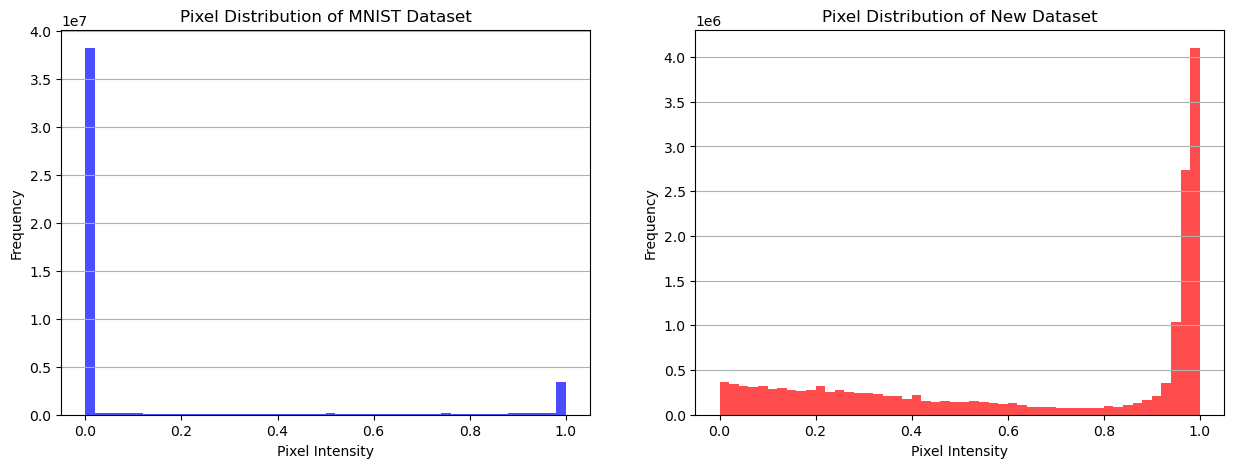

In [35]:
# Plot the difference in the distribution of the pixels of mnist and new dataset
def plot_pixel_distribution(images1, images2, num_bins=50):
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1)
    plt.hist(images1.flatten(), bins=num_bins, color='blue', alpha=0.7)
    plt.title("Pixel Distribution of MNIST Dataset")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.grid(axis='y')
    plt.subplot(1, 2, 2)
    plt.hist(images2.flatten(), bins=num_bins, color='red', alpha=0.7)
    plt.title("Pixel Distribution of New Dataset")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.grid(axis='y')
    plt.show()
    
# Load the MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train_flattened = flatten_images(X_train)
X_test_flattened = flatten_images(X_test)
X_train_normalized = normalize_data(X_train_flattened)
X_test_normalized = normalize_data(X_test_flattened)


# Plot the pixel distribution of the MNIST and new dataset
plot_pixel_distribution(X_train_normalized, images_normalized)


In [36]:
# Print the distribution of the numbers in the new dataset
unique, counts = np.unique(labels, return_counts=True)
print(dict(zip(unique, counts)))

{0: 2236, 1: 2241, 2: 2233, 3: 2202, 4: 2179, 5: 2126, 6: 2121, 7: 2116, 8: 2085, 9: 2016}


In [38]:
# Print the distribution of the numbers in the mnist dataset
unique, counts = np.unique(y_train, return_counts=True)
print(dict(zip(unique, counts)))

{0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


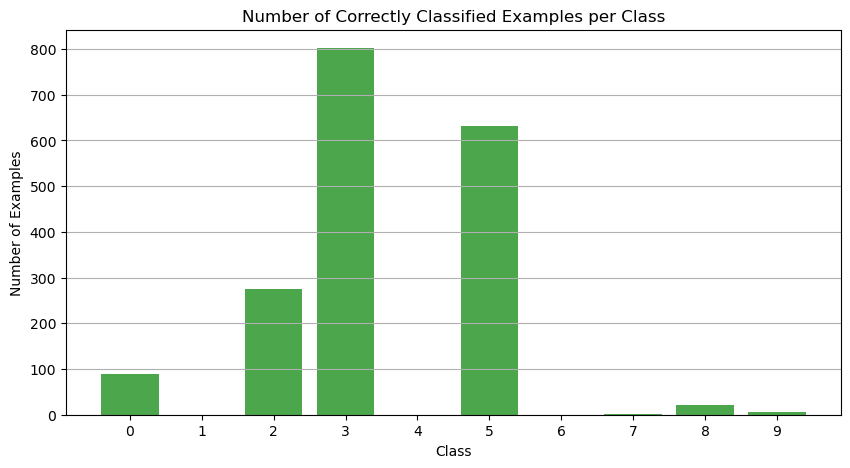

In [39]:
# Plot number of correctly classified examples for each class

def plot_correctly_classified_per_class(true_labels, predicted_labels, num_classes=10):
    correct_per_class = np.zeros(num_classes)
    for i in range(num_classes):
        correct_per_class[i] = np.sum((true_labels == i) & (predicted_labels == i))
    plt.figure(figsize=(10, 5))
    plt.bar(np.arange(num_classes), correct_per_class, color='green', alpha=0.7)
    plt.title("Number of Correctly Classified Examples per Class")
    plt.xlabel("Class")
    plt.ylabel("Number of Examples")
    plt.xticks(np.arange(num_classes))
    plt.grid(axis='y')
    plt.show()
    
plot_correctly_classified_per_class(correctly_classified_labels, correctly_classified_predictions)


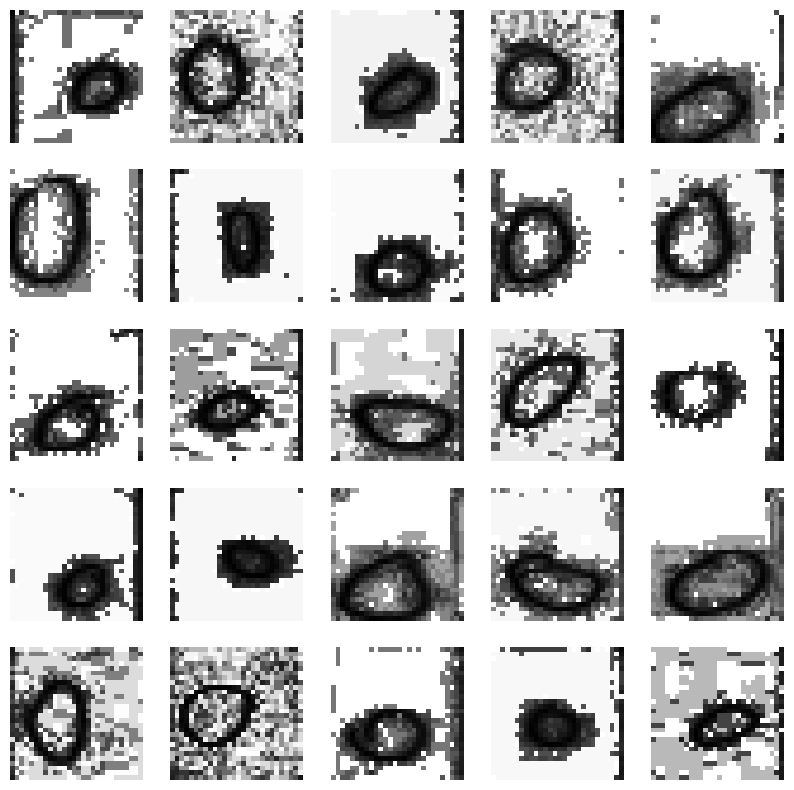

In [41]:
# Display them in a grid
def display_images_in_grid(images, num_rows, num_cols, figsize=(10, 10)):
    plt.figure(figsize=figsize)
    for i in range(num_rows * num_cols):
        plt.subplot(num_rows, num_cols, i + 1)
        plt.imshow(images[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
    plt.show()
    
# Display the correctly classified examples in a grid
display_images_in_grid(correctly_classified_images, 5, 5)

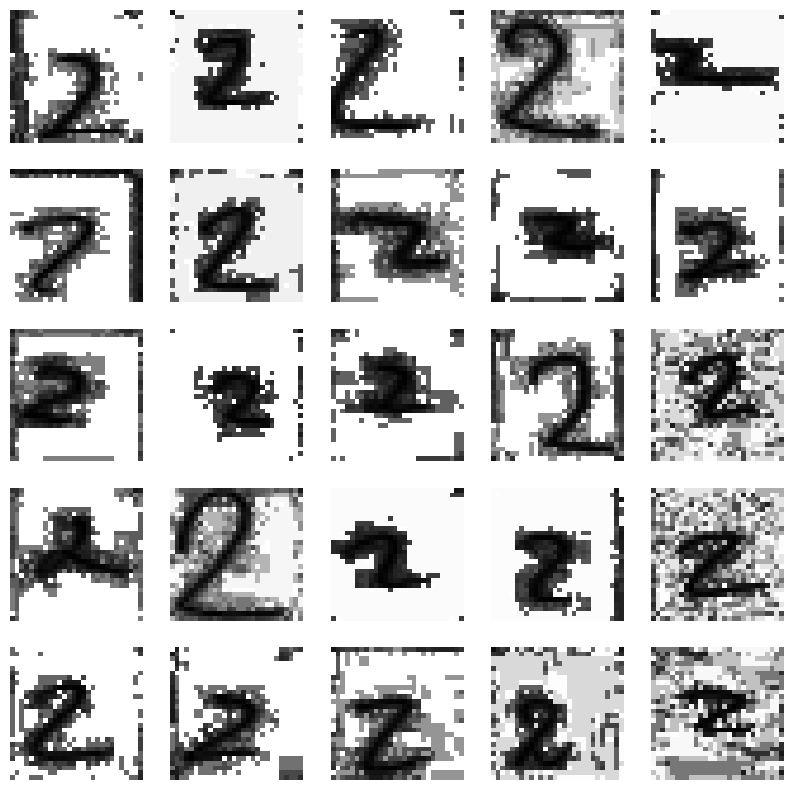

In [42]:
# Exclude 0 from the visualization
def display_images_in_grid(images, num_rows, num_cols, figsize=(10, 10)):
    plt.figure(figsize=figsize)
    for i in range(num_rows * num_cols):
        plt.subplot(num_rows, num_cols, i + 1)
        plt.imshow(images[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
    plt.show()
    
# Display the correctly classified examples in a grid
display_images_in_grid(correctly_classified_images[correctly_classified_labels != 0], 5, 5)